# Short conditional Gaussian gates: construction, corrections, results

For the latest higher-order, phase-cycle and shorter squeezing comparisons,
read [the focused follow-up](modulated_swap200.ipynb).

The current minimum swap time is **200 ns**. This historical sweep includes
stronger couplings; use the focused notebook for current feasible CD and
squeezing recommendations.

Goal: 8 dB conditional squeezing and a pi-relative conditional number rotation,
with at least **99% coherent gate fidelity over the complete g/e × n=0..8 input
subspace**. Relative phases count. Every qubit pi envelope lasts 30 ns.

Constant pump phase allows simpler repeated qubit blocks. Smooth **10 ns pump
I/Q transitions** gave these earlier short gates. The table below contains
independently verified played-waveform results in the ideal, lossless JC model
with a perfect two-level qubit and zero static chi.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS


import os
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import json,hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
import cd_trains as cd
import hardware_check as hw
from acadia.sample_arithmetic import sample_to_complex
ROOT=PROJECT_ROOT;DATA=ROOT/'runs/constant_pump_gaussian';V=DATA/'verified'
FIG=DATA/'figures';FIG.mkdir(exist_ok=True)
def read(name):return json.loads((DATA/name).read_text())
def certificate(name):return json.loads((V/(name+'.json')).read_text())
def source(name):return read(name+'.json')
def finish(name):
    plt.gcf().savefig(FIG/(name+'.png'),dpi=160,bbox_inches='tight');plt.show()
def replay(name):
    r=certificate(name);w=np.load(V/(name+'_words.npz'))
    digest=hashlib.sha256(w['qubit'].tobytes()+w['sideband'].tobytes()).hexdigest()
    assert digest==r['word_sha256']
    qs,ss=hw.dac_scales(.6)
    q=hw.rfdc_interpolate(sample_to_complex(w['qubit'])).conj()/qs*(np.pi/cd.PI_TIME)
    s=hw.rfdc_interpolate(sample_to_complex(w['sideband']))/ss*(np.pi/(2*.6))
    sp=cd.Space(r['levels'],9);initial=np.eye(2*r['levels'],dtype=complex)[:,sp.inputs]
    output=hw.propagate(q,s,initial,cd.DT/8,order=16)
    output*=np.exp(-1j*r['qubit_frame_Rz']*sp.z/2)[:,None]
    saved=np.load(V/(name+'_columns.npz'));target=saved['target']
    difference=float(np.max(abs(output-saved['output'])))
    fidelity=float(abs(np.vdot(target,output)/18)**2)
    assert difference<1e-10 and abs(fidelity-r['fidelity'])<1e-12
    print('FRESH INDEPENDENT REPLAY',name,'18inputcolumns;',output.size,
          'amplitudes;maxdifference',difference,'F',fidelity)
    return r,output,target

names=['squeeze_compression_07','squeeze_lifted_n192_b96','strength_squeeze_swap300',
       'rotation_lifted_n256_b128','strength_rotation_swap150']
records=[certificate(n) for n in names]
rows=[]
for name,r in zip(names,records):
    a=source(name);job=a['job']
    rows.append(dict(gate='8dB squeeze' if r['gate']=='squeeze' else 'pi-relative rotation',
                     pattern=(str(job['block'])+' pi pulses, repeated twice' if 'lifted' in name else
                              'individually corrected pi axes'),
                     sideband='constant phase' if r['pump_phase_constant'] else '10ns smooth IQ',
                     swap_ns=(a.get('equivalent_swap_ns') or job['swap']*1000),
                     command_us=r['command_us'],full_RFDC_window_us=r['RFDC_window_us'],
                     coherent_gate_F=r['fidelity'],worst_basis_F=r['worst_basis_fidelity']))
display(pd.DataFrame(rows))


,gate,pattern,sideband,swap_ns,command_us,full_RFDC_window_us,coherent_gate_F,worst_basis_F
0,8dB squeeze,individually corrected pi axes,constant phase,353.947368,4.81,4.854219,0.990183,0.959283
1,8dB squeeze,"96 pi pulses, repeated twice",constant phase,367.423461,5.77,5.814219,0.990333,0.962158
2,8dB squeeze,individually corrected pi axes,10ns smooth IQ,300.000000,3.85,3.894219,0.994601,0.977186
3,pi-relative rotation,"128 pi pulses, repeated twice",constant phase,282.842712,7.69,7.734219,0.990514,0.984134
4,pi-relative rotation,individually corrected pi axes,10ns smooth IQ,150.000000,2.89,2.934219,0.995042,0.988584


## 1. Targets and the Trotter seed

With $\sigma_z=+1$ on g, the fixed targets are

$$S_z(r)=e^{(r/2)\sigma_z(a^2-a^{\dagger2})},\qquad
r=\frac{8\ln10}{20}=0.921034,\qquad U_\chi=e^{-i(\pi/2)\sigma_z n}.$$

For the 18 target columns $T$ and propagated columns $V$,

$$F_{\mathrm{proc}}=\frac{|\operatorname{Tr}(T^\dagger V)|^2}{18^2}.$$

Leaked amplitude is retained. This process metric is not a worst-input
guarantee. Each sequence includes one declared final qubit $R_z$.

Write $H_{\mathrm{JC}}/g=(\sigma_xX+\sigma_yP)/2$, with
$X=a+a^\dagger$ and $P=i(a^\dagger-a)$. Qubit conjugations change the effective
JC Hamiltonian while the pump phase stays fixed:

| Target | Hermitian generators | Commutator |
|---|---|---|
| Squeezing | $A=H_{\mathrm{JC}}/g$, $B=-\sigma_xA\sigma_x$ | $\sigma_z(a^2-a^{\dagger2})$ |
| Number rotation | $A=H_{\mathrm{JC}}/g$, $B=R_z(-\pi/2)AR_z^\dagger(-\pi/2)$ | $-i[\sigma_z(2n+1)-I]$ |

The number-rotation seed has a known scalar and qubit-Z correction.
Two pi pulses about axes separated by $\varphi/2$ synthesize a qubit Z rotation
of $\varphi$ in this instantaneous-control construction.

A chronological $A,B,-A,-B$ loop gives

$$C_\epsilon=e^{i\epsilon B}e^{i\epsilon A}e^{-i\epsilon B}e^{-i\epsilon A},
\qquad \log C_\epsilon=\epsilon^2[A,B]+O(\epsilon^3).$$

Pairing $C_\epsilon$ with $C_{-\epsilon}$ cancels the cubic term. The reference
below uses instantaneous controls: higher order improves asymptotic convergence
but can have a large coefficient, so it is not automatically faster at a finite
number of loops.

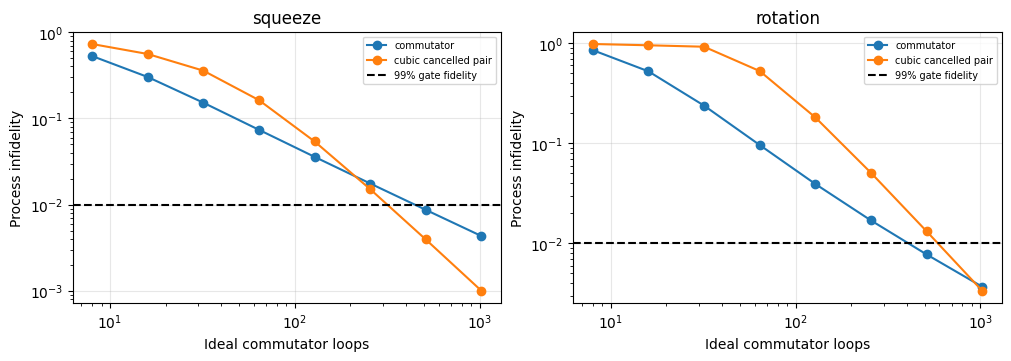

In [2]:

reference=pd.DataFrame(read('instantaneous_commutator_reference.json'))
fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
for ax,gate in zip(axes,['squeeze','rotation']):
    for method,group in reference[reference.gate==gate].groupby('method'):
        ax.loglog(group.loops,1-group.fidelity,'o-',label=method.replace('_',' '))
    ax.axhline(.01,color='k',ls='--',label='99% gate fidelity')
    ax.set(title=gate,xlabel='Ideal commutator loops',ylabel='Process infidelity')
    ax.grid(alpha=.3);ax.legend(fontsize=7)
finish('gaussian_trotter_reference')


## 2. Correct the errors while the qubit pulse is on

JC evolution continues during every 30 ns pi pulse. The fit evolves both
controls simultaneously. A loop-area argument or a palindrome of phase labels
does not replace the full gate calculation.

The constant-phase repeated designs begin with the native commutator seed,
continue coupling and target strength together, and correct the axes in two
**identical superblocks**. They have 96 or 128 independent qubit axes.

The shortest smooth-phase designs continue the best previous Gaussian fits.
Their variables are the qubit axes, pump plateau phases and one common pump
strength. These fastest rows are continuations of earlier solutions; they are
not proofs of a particular Trotter order.

Each smooth-phase forward objective packs SDK int16 words, applies the RFDC
filters and propagates all 18 inputs. No individual waveform sample is a fit
variable. The unsuccessful shorter motifs remain in the saved search data.

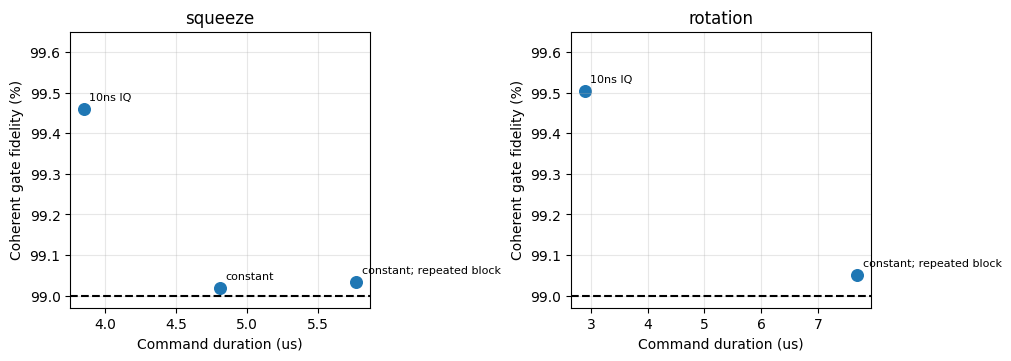

Search-cutoff starting score and converged final certificate:
strength_squeeze_swap300 initial F 0.9749480313252554 final F 0.9946012929575878 actual-playback evaluations 42
strength_rotation_swap150 initial F 0.9515698619901339 final F 0.9950417421246439 actual-playback evaluations 25


In [3]:

fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
for ax,gate in zip(axes,['squeeze','rotation']):
    selected=[r for r in records if r['gate']==gate]
    ax.scatter([r['command_us'] for r in selected],[100*r['fidelity'] for r in selected],s=70)
    for r in selected:
        label='constant' if r['pump_phase_constant'] else '10ns IQ'
        if 'lifted' in r['name']:label+='; repeated block'
        ax.annotate(label,(r['command_us'],100*r['fidelity']),xytext=(4,6),textcoords='offset points',fontsize=8)
    ax.axhline(99,color='k',ls='--');ax.set(title=gate,xlabel='Command duration (us)',ylabel='Coherent gate fidelity (%)',ylim=(98.97,99.65))
    ax.grid(alpha=.3)
finish('gaussian_useful_results')
print('Search-cutoff starting score and converged final certificate:')
for name in ['strength_squeeze_swap300','strength_rotation_swap150']:
    r=source(name)
    print(name,'initial F',r['initial_fidelity'],'final F',certificate(name)['fidelity'],
          'actual-playback evaluations',r['evaluations'])


## 3. Literal pulse prescription

Every qubit envelope is a 30 ns pi pulse; its phase sets the axis. A repeated
sequence plays its listed half twice. The pump has one 5 ns ramp at each outer
end, with no added ramp between repeats.

For neighboring pump plateaus $z_0,z_1$, the smooth designs program

$$z(u)=[1-h(u)]z_0+h(u)z_1,\qquad
h(u)=10u^3-15u^4+6u^5,\qquad 0\le u\le1,$$

over the last 5 ns / first 5 ns of adjacent cells. The RFDC filters those samples.
The physical qubit DAC phase is minus its model axis; the pump sign is unchanged.
NCOs stay fixed and no extra phase chirp is inserted.

strength_squeeze_swap300 apply final qubit Rz(rad)= 5.788583994694756


Complete pulse table: [CSV](runs/constant_pump_gaussian/verified/strength_squeeze_swap300_sequence.csv).

strength_rotation_swap150 apply final qubit Rz(rad)= 0.5847534171111612


Complete pulse table: [CSV](runs/constant_pump_gaussian/verified/strength_rotation_swap150_sequence.csv).

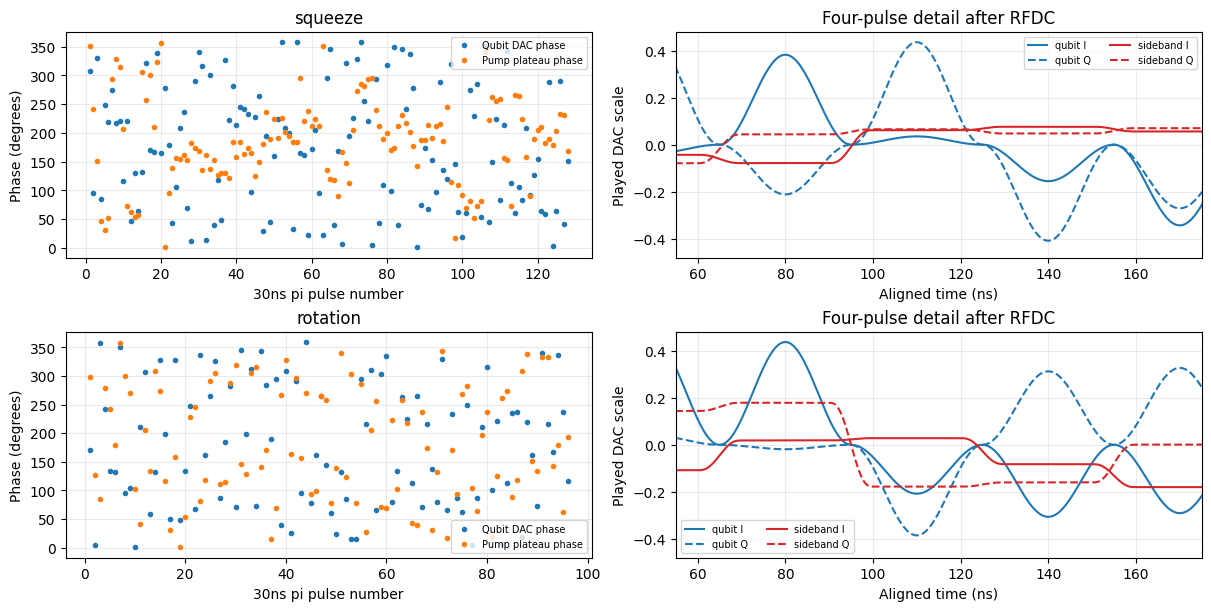

squeeze_lifted_n192_b96 : repeat the identical half twice; final Rz(rad)= -5.542702969501703


[Repeated-block CSV](runs/constant_pump_gaussian/verified/squeeze_lifted_n192_b96_sequence.csv)

rotation_lifted_n256_b128 : repeat the identical half twice; final Rz(rad)= -4.74419992135117


[Repeated-block CSV](runs/constant_pump_gaussian/verified/rotation_lifted_n256_b128_sequence.csv)

In [4]:

fig,axes=plt.subplots(2,2,figsize=(12,6),constrained_layout=True)
for row,name in zip(axes,['strength_squeeze_swap300','strength_rotation_swap150']):
    r=certificate(name);table=pd.read_csv(V/(name+'_sequence.csv'))
    row[0].plot(table.pulse,table.qubit_DAC_deg,'.',label='Qubit DAC phase')
    row[0].plot(table.pulse,table.pump_plateau_DAC_deg,'.',label='Pump plateau phase')
    row[0].set(title=r['gate'],xlabel='30ns pi pulse number',ylabel='Phase (degrees)');row[0].legend(fontsize=7)
    words=np.load(V/(name+'_words.npz'))
    for key,color in [('qubit','C0'),('sideband','C3')]:
        programmed=sample_to_complex(words[key]);played=hw.rfdc_interpolate(programmed)
        t=np.arange(len(played))*.15625-22.65625
        row[1].plot(t,played.real,color=color,label=key+' I')
        row[1].plot(t,played.imag,color=color,ls='--',label=key+' Q')
    row[1].set(xlim=(55,175),xlabel='Aligned time (ns)',ylabel='Played DAC scale',title='Four-pulse detail after RFDC')
    row[1].legend(fontsize=7,ncol=2)
    for ax in row:ax.grid(alpha=.25)
    print(name,'apply final qubit Rz(rad)=',r['qubit_frame_Rz'])
    display(Markdown(f"Complete pulse table: [CSV](runs/constant_pump_gaussian/verified/{name}_sequence.csv)."))
finish('gaussian_played_sequences')
for name in ['squeeze_lifted_n192_b96','rotation_lifted_n256_b128']:
    print(name,': repeat the identical half twice; final Rz(rad)=',certificate(name)['qubit_frame_Rz'])
    display(Markdown(f"[Repeated-block CSV](runs/constant_pump_gaussian/verified/{name}_sequence.csv)"))


## 4. Strength sweep: retuned gates versus calibration sensitivity

Shorter swap time means stronger coupling: $g=\pi/(2t_{\mathrm{swap}})$.

The upper row retunes phases at each fixed strength, including the 10 ns pump
transitions. Grey curves show the final shorter-duration screens. These are
achieved local-fit scores, not global maxima or impossibility bounds.
Every plotted map point has separately converged output and target cutoffs.

The lower row holds each selected sequence, duration and final frame fixed.
It measures calibration tolerance, rather than a reoptimized envelope.

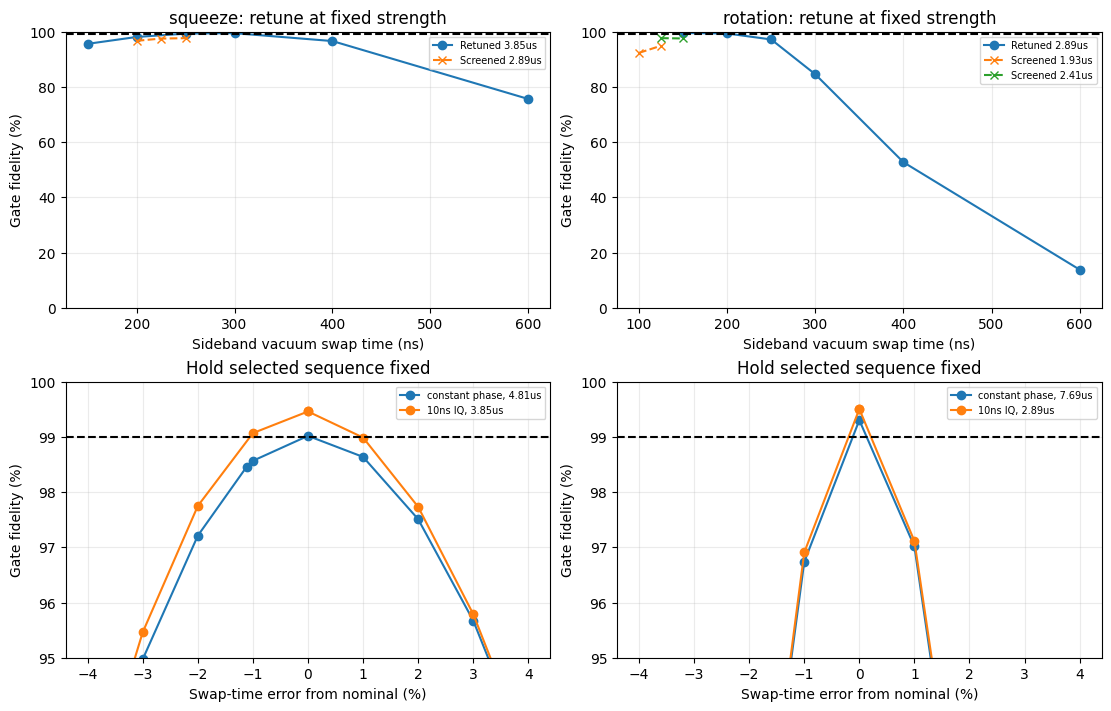

Retuned Gaussian map: 12 strength points. Additional shorter screens: 7


In [5]:

curves=read('strength_sensitivity.json')['results']
maps=read('gaussian_strength_played_summary.json')
shorter=read('shorter_played_summary.json')
fig,axes=plt.subplots(2,2,figsize=(11,7),constrained_layout=True)
chosen=['squeeze_compression_07','strength_squeeze_swap300',
        'rotation_compression_10','strength_rotation_swap150']
for col,gate in enumerate(['squeeze','rotation']):
    group=sorted([r for r in maps if r['job']['gate']==gate],key=lambda r:r['equivalent_swap_ns'])
    duration=group[0]['command_us']
    axes[0,col].plot([r['equivalent_swap_ns'] for r in group],
                     [100*r['converged_fidelity'] for r in group],'o-',label=f'Retuned {duration:.2f}us')
    for n in sorted(set(r['job']['cells'] for r in shorter if r['job']['gate']==gate)):
        group=sorted([r for r in shorter if r['job']['gate']==gate and r['job']['cells']==n],
                     key=lambda r:r['equivalent_swap_ns'])
        axes[0,col].plot([r['equivalent_swap_ns'] for r in group],
                        [100*r['converged_fidelity'] for r in group],'x--',label=f'Screened {group[0]["command_us"]:.2f}us')
    for item in [c for c in curves if c['gate']==gate and c['name'] in chosen]:
        frame=pd.DataFrame(item['results']).sort_values('swap_ns')
        r=certificate(item['name'])
        label=('constant phase' if r['pump_phase_constant'] else '10ns IQ')+f", {r['command_us']:.2f}us"
        nominal=item['nominal_swap_ns'];near=frame[abs(frame.swap_ns/nominal-1)<.05]
        axes[1,col].plot(100*(near.swap_ns/nominal-1),100*near.fidelity,'o-',label=label)
    axes[0,col].set(title=gate+': retune at fixed strength',
                    xlabel='Sideband vacuum swap time (ns)',ylabel='Gate fidelity (%)',ylim=(0,100))
    axes[1,col].set(title='Hold selected sequence fixed',xlabel='Swap-time error from nominal (%)',
                    ylabel='Gate fidelity (%)',ylim=(95,100))
    for ax in axes[:,col]:ax.axhline(99,color='k',ls='--');ax.grid(alpha=.25);ax.legend(fontsize=7)
finish('gaussian_strength_dependence')
print('Retuned Gaussian map:',len(maps),'strength points. Additional shorter screens:',len(shorter))


## 5. Fresh independent simulation

The following cell reloads the integer words and independently evolves all 18
inputs again. Accepted gates increase the output cutoff until both output and
target columns change by less than $10^{-9}$ in norm. Squeezing requires 256
levels here; one repeated rotation requires 320. The tested input range remains
n=0..8.

FRESH INDEPENDENT REPLAY strength_squeeze_swap300 18inputcolumns; 9216 amplitudes;maxdifference 1.0454315885429113e-14 F 0.9946012929575887


FRESH INDEPENDENT REPLAY strength_rotation_swap150 18inputcolumns; 3456 amplitudes;maxdifference 8.16995163024819e-15 F 0.9950417421246424


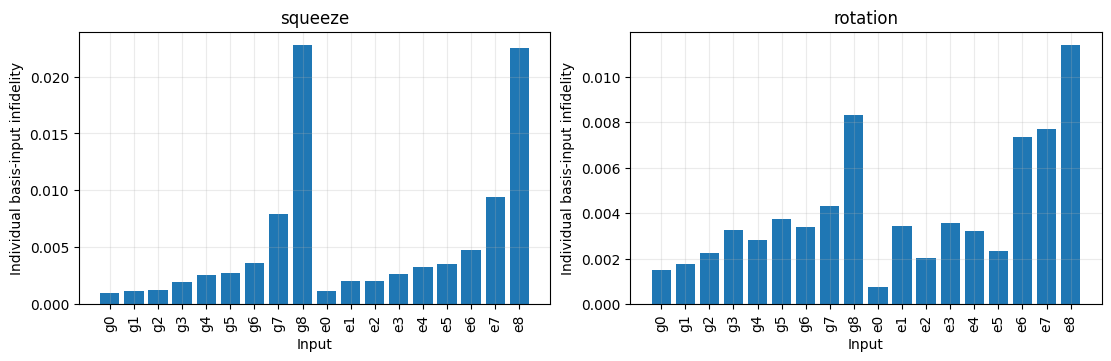

Fresh Gaussian totals:2gates;36inputcolumns; 12672 complex amplitudes compared.


In [6]:

fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
amplitudes=0
for ax,name in zip(axes,['strength_squeeze_swap300','strength_rotation_swap150']):
    r,out,T=replay(name);amplitudes+=out.size
    errors=1-abs(np.sum(T.conj()*out,axis=0))**2
    ax.bar(np.arange(18),errors)
    ax.set(title=r['gate'],ylabel='Individual basis-input infidelity',xlabel='Input')
    ax.set_xticks(range(18),[f'g{n}' for n in range(9)]+[f'e{n}' for n in range(9)],rotation=90);ax.grid(alpha=.25)
finish('gaussian_input_errors')
print('Fresh Gaussian totals:2gates;36inputcolumns;',amplitudes,'complex amplitudes compared.')


The 99% process goal is reached in **3.85 us for 8 dB squeezing** and
**2.89 us for the pi-relative number rotation**, with smooth 10 ns pump I/Q.
Constant-phase alternatives and identical-superblock constructions are shown
above. These are achieved results within the stated search, not global minimum
times. The [README](../README.md) links complete words, CSVs and search coverage.